<a href="https://colab.research.google.com/github/fdac25/MP2/blob/main/Vis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt



In [4]:
df = pd.read_csv("pvickery_project_summary.csv", sep=";")
df.columns = ['project','commit','author','time','message']
df['Month'] = pd.to_datetime(df['time'], unit='s').dt.strftime('%Y-%m')
df.head()

,project,commit,author,time,message,Month
0,epam_med3web,0042d7f2465621277a4d11e5995304390e1c82b6,DanilRostov <31970322+DanilRostov@users.norepl...,1684534336,Merge pull request #153 from epam/feature/impr...,2023-05
1,epam_med3web,00ae3a2a73d11edd95b6fc879ef368df8b015141,Daniil <krtdaniil@gmail.com>,1680803564,fix(EPMUII-3184): merge issues\n,2023-04
2,epam_med3web,0142c9a832b389eb1c24c6cb84a22de2f85c205f,Mariia Verdina <mariia_verdina@epam.com>,1530640190,Merge branch 'master' of https://github.com/ep...,2018-07
3,epam_med3web,01450cb24cf2641c78167eca57b7e238ebd65b90,Mariia Verdina <mariia_verdina@epam.com>,1522407313,add gui for new 3d mode\n\n- rename old 3d mod...,2018-03
4,epam_med3web,016c3e985263bbc4c8fa9b19d0a336cfdf4dc0ff,Kateryna Sliepchenko <catherine.slepchenko@gma...,1693909935,add additional render for canvas\n,2023-09


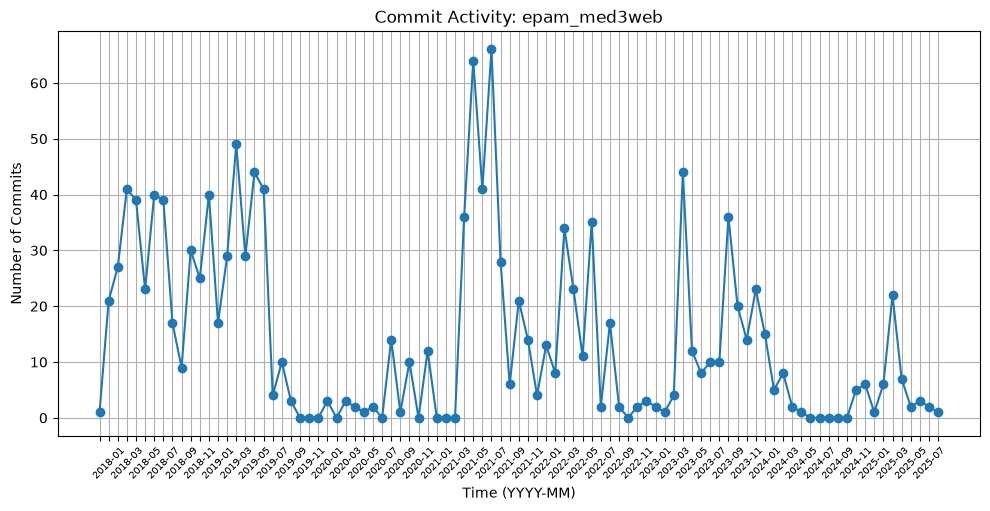

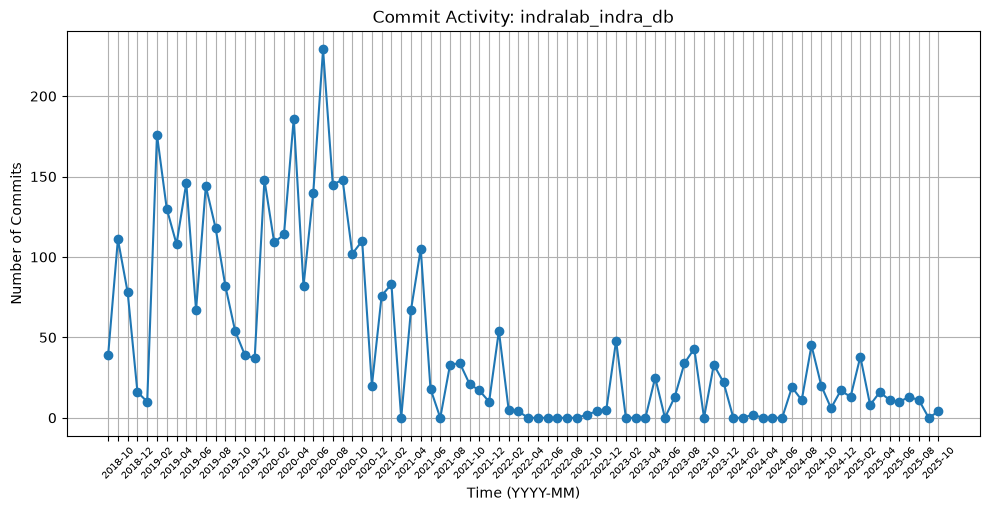

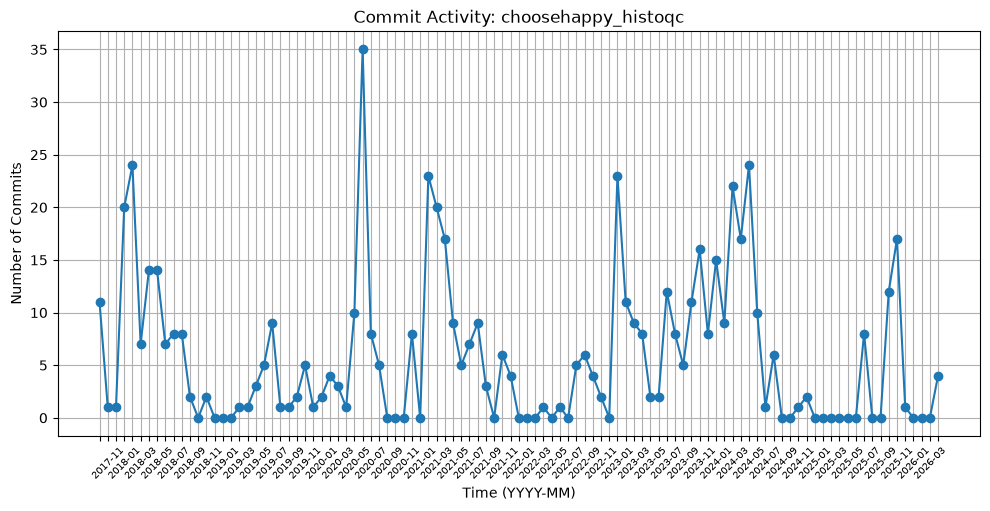

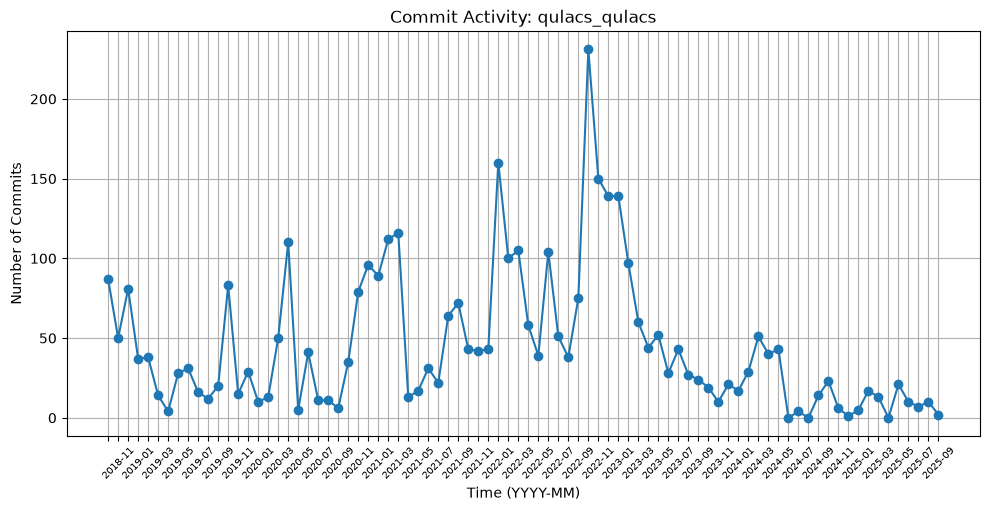

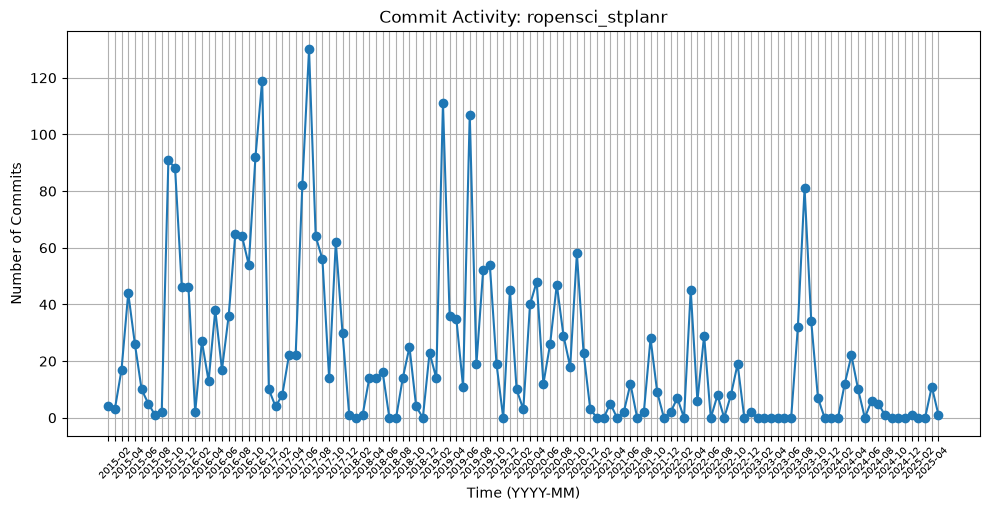

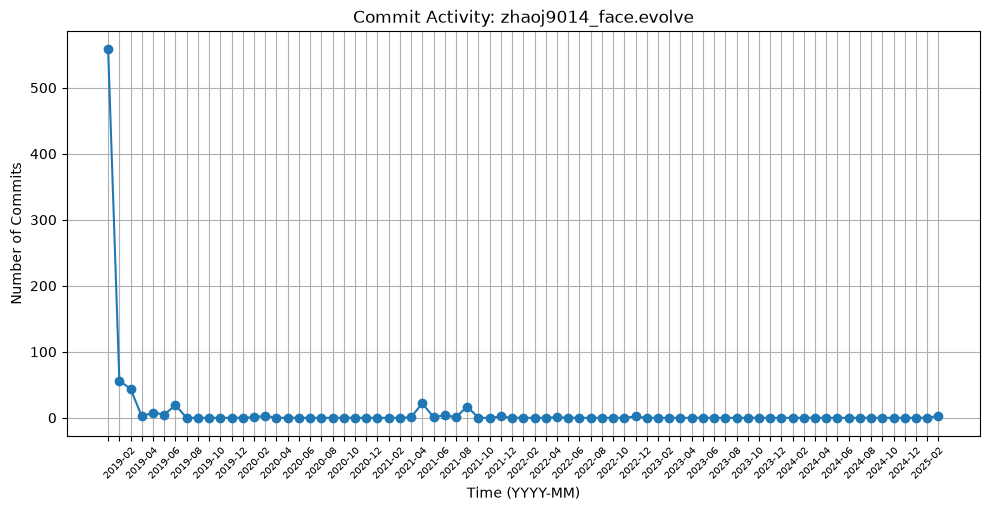

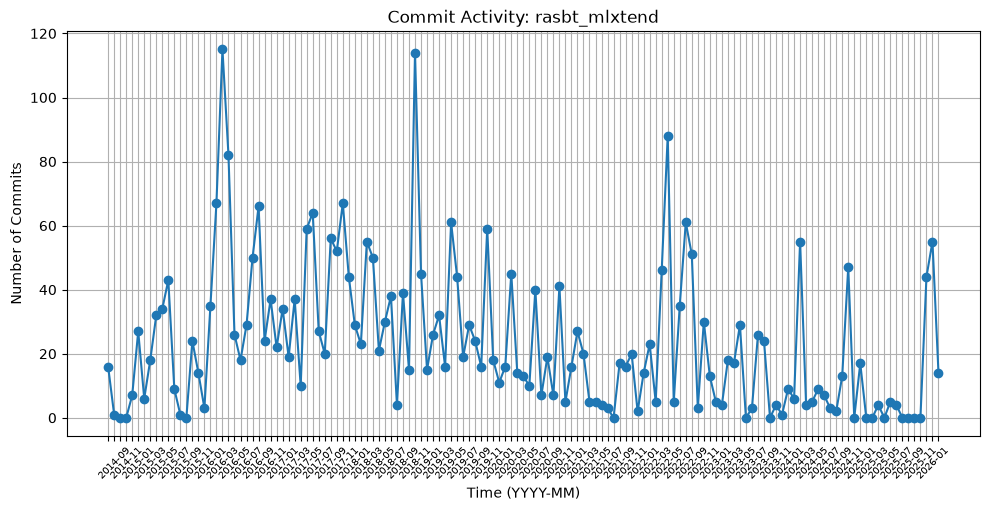

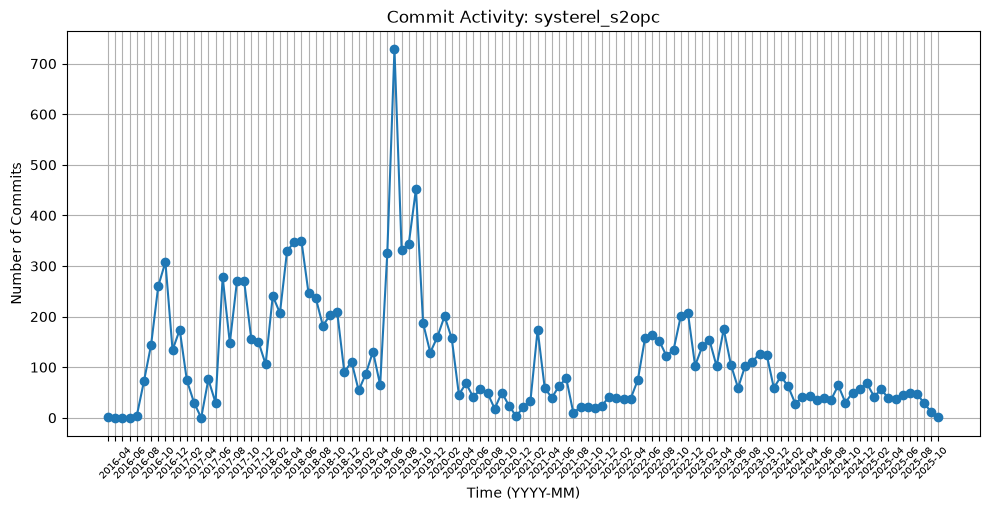

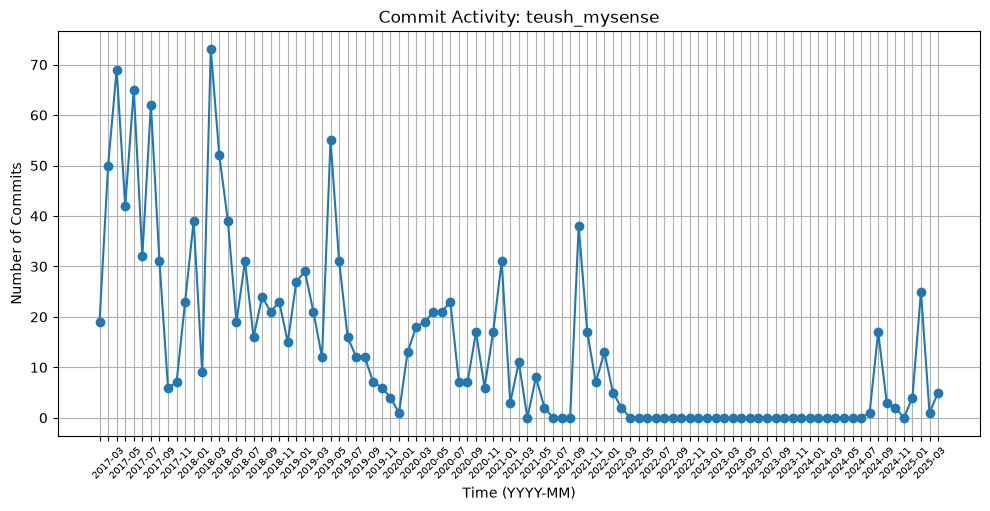

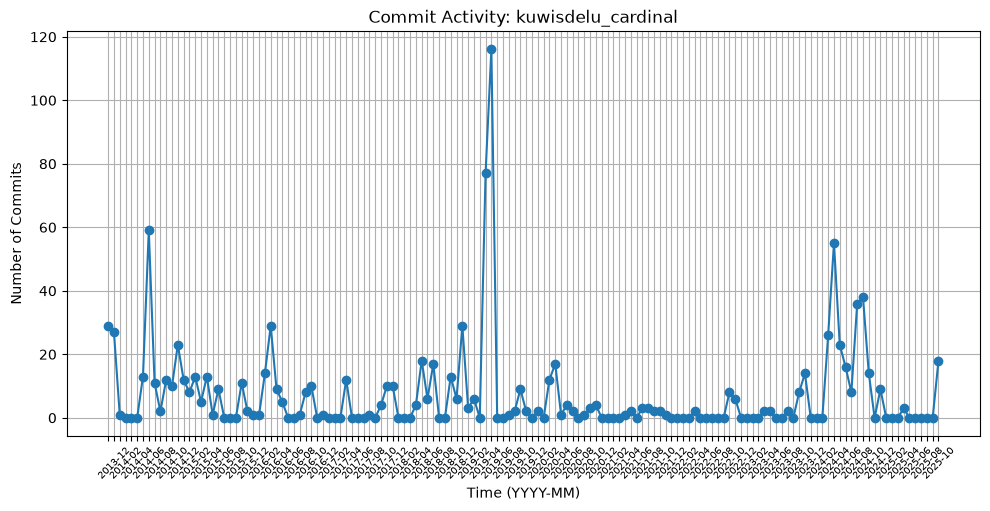

In [5]:
import matplotlib.ticker as ticker

for prj in df['project'].unique():
    df1 = df[df['project']==prj]
    df2 = df1.groupby('Month').size().reset_index(name='Commits')
    monthly_counts = df2
    monthly_counts['time'] = pd.to_datetime(monthly_counts['Month'])
    full_date_range = pd.DataFrame({'time': pd.date_range(start=monthly_counts['time'].min(), end=monthly_counts['time'].max(), freq='MS')})
    monthly_counts = pd.merge(full_date_range, monthly_counts, on='time', how='left').fillna(0)
    monthly_counts['Month'] = monthly_counts['time'].dt.strftime('%Y-%m')
    # Plot
    plt.figure(figsize=(10,5))
    plt.plot(monthly_counts["Month"], monthly_counts["Commits"], marker="o", linestyle="-")
    plt.xlabel("Time (YYYY-MM)")
    plt.ylabel("Number of Commits")
    plt.title("Commit Activity: "+prj)
    plt.grid(True)
    plt.tight_layout()
    ax =  plt.gca()
    for label in ax.xaxis.get_ticklabels()[::2]:
        label.set_visible(False)
    plt.xticks(rotation=45, fontsize=7)
    plt.savefig("pvickery_timeseries_"+prj+".png", dpi=600)
    plt.show()
    plt.close()

# Identify the Longest Inactivity Gap

2022-02 to 2023-04

Add all that info to netid_project_stats.csv

In [ ]:

github = {
    'choosehappy_histoqc': (331, 118, 'September 16, 2026'),
    'epam_med3web': (368, 105, 'September 24, 2026'),
    'indralab_indra_db': (22, 12, 'July 9, 2026'),
    'kuwisdelu_cardinal': (81, 18, 'July 30, 2026'),
    'qulacs_qulacs': (529, 147, 'September 29, 2026'),
    'rasbt_mlxtend': (5200, 920, 'September 29, 2026'),
    'ropensci_stplanr': (443, 68, 'April 17, 2025'),
    'systerel_s2opc': (28, 6, 'September 30, 2026'),
    'teush_mysense': (71, 18, 'September 1, 2026'),
    'zhaoj9014_face.evolve': (3600, 759, 'March 19, 2025')
}

results = []

for prj in df['project'].unique():
    d = df[df['project'] == prj].copy()
    d['time'] = pd.to_datetime(d['time'], unit='s')
    monthly = d.groupby(d['time'].dt.to_period('M')).size()

    monthly = monthly.reindex(
        pd.period_range(monthly.index.min(), monthly.index.max(), freq='M'),
        fill_value=0
    )

    # Group consecutive zero-commit months
    zero = monthly.eq(0)
    groups = (zero != zero.shift()).cumsum()
    gaps = monthly[zero].groupby(groups[zero]).agg(['size'])

    if len(gaps):
        longest = gaps['size'].max()
        longest_group = gaps.index[gaps['size'] == longest][0]
        gap_months = monthly[groups == longest_group].index
        start, end = str(gap_months[0]), str(gap_months[-1])
        after = int(monthly[monthly.index > gap_months[-1]].sum())
    else:
        longest, start, end = 0, '', ''
        after = int(monthly.sum())

    stars, forks, last_commit = github[prj]

    results.append({
        'project': prj,
        'number of commits': d['commit'].nunique(),
        'number of authors': d['author'].nunique(),
        'max time': d['time'].max(),
        'min time': d['time'].min(),
        'number of stars': stars,
        'number of forks': forks,
        'last commit date': last_commit,
        'LongestGapStart': start,
        'LongestGapEnd': end,
        'LongestGapLength': int(longest),
        'NumCommitsAfterLastGap': after,
        'NumberOfGapsInTimeline': sum(
            len(monthly[groups == g]) >= 3
            for g in groups[zero].unique()
        ),
        'ActivityPattern': ''
    })

stats = pd.DataFrame(results)
stats.to_csv('pvickery_project_stats.csv', index=False)

In [2]:
output = pd.read_csv("pvickery_project_stats.csv", sep=",")
output

,project,number of commits,number of authors,max time,min time,number of stars,number of forks,last commit date,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,NumberOfGapsInTimeline,ActivityPattern
0,epam_med3web,1326,79,2025-08-21 01:14:36,2017-12-25 15:02:37,368,105,"September 24, 2026",2024-06,2024-10,5,55,3,irregular
1,indralab_indra_db,3888,24,2025-10-16 21:51:36,2018-09-20 21:16:31,22,12,"July 9, 2026",2022-04,2022-09,6,473,3,irregular
2,choosehappy_histoqc,610,43,2026-04-13 20:00:04,2017-10-16 13:29:10,331,118,"September 16, 2026",2025-01,2025-06,6,42,5,irregular
3,qulacs_qulacs,3803,113,2025-09-01 00:44:13,2018-10-05 05:24:32,529,147,"September 29, 2026",2024-06,2024-06,1,133,0,irregular
4,ropensci_stplanr,2753,50,2025-05-03 08:48:58,2015-01-30 08:36:50,443,68,"April 17, 2025",2023-02,2023-07,6,223,3,irregular
5,zhaoj9014_face.evolve,750,11,2025-03-20 02:45:06,2019-01-04 02:22:17,3600,759,"March 19, 2025",2023-01,2025-02,26,3,5,declining
6,rasbt_mlxtend,3288,213,2026-02-27 08:53:23,2014-08-14 01:56:16,5200,920,"September 29, 2026",2025-08,2025-11,4,113,1,irregular
7,systerel_s2opc,13436,51,2025-11-03 13:31:44,2016-03-14 15:11:00,28,6,"September 30, 2026",2016-04,2016-06,3,13434,1,irregular
8,teush_mysense,1364,6,2025-04-09 15:25:56,2017-02-22 14:51:50,71,18,"September 1, 2026",2022-04,2024-07,28,58,2,declining
9,kuwisdelu_cardinal,1036,29,2025-10-14 18:19:22,2013-11-17 11:46:32,81,18,"July 30, 2026",2022-05,2022-09,5,288,12,U-shaped


# Interpretation

* epam_med3web - This project had its most consistent activity in 2018, with some months of higher activity in 2021, 2022, 2023, and 2025. The moments of lower activity do not follow any pattern, so I chose irregular as the activity pattern. There are 3 inactivity gaps in this project.
* indralab_indra_db - Activity is at its highest from 2018 to 2020, with a decrease in activity in 2021. The longest inactivity gap is in 2022, with an increase in activity at the end of 2022. There are some smaller increases in activity in 2023 before decrease, in addition to similar increases in 2024 and 2025. Because it is not consistently rising or declining, and the changes in activity do not follow a pattern, I have classified it as irregular. There are 3 inactivity gaps in this project.
* choosehappy_histoqc - The activity fluctuates a lot with this project, with multiple major increases and decreases in activity. There are peaks in 2018, 2020, 2021, 2023, 2024, and 2025. There is not a consistent trend with these variations, so I have selected irregular. There are 5 inactivity gaps in this project.
* qulacs_qulacs - Activity is at its highest from 2018 to 2022, peaking at 2022. It then decreases starting with 2023, with slight increases in activity in 2024 and 2025. Because it is not consistently declining throughout the project's history, I have selected irregular. There are 0 inactivity gaps in this project.
* ropensci_stplanr - The project had its highest months of activity from 2016 to 2017, with a significant decrease in 2018, then increasing again in 2019. Activity continues to fluctuate from 2021, with a final significant decrease in activity from 2024 to 2025. As the fluctuation does not follow any pattern, I have selected irregular. The project has 3 inactivity gaps.
* zhaoj9014_face.evolve - The project experiences the majority of its activity in January of 2019, decreasing significantly and having few months after that have any activity. Because of this, I have selected declining. There are 5 inactivity gaps in this project.
* rasbt__mlxtend - Activity increased from 2014 to through 2016 and remained for 2017 and 2018, except for some months of lower activity. From 2019 to 2021, activity generally decreased. It then increased in 2022, then became much lower after 2023 except for occasional months of higher activity. There is 1 inactivity gap in this project.
* systerel_s2opc - Activity increased from 2016 through 2019, but there were some fluctuations where certain months had lower activity. There was then a significant decrease in activity from 2020 through 2021. Activity increased in 2022 and remained at a similar level in 2023, before decreasing again in 2024 and 2025. Because there is not a pattern in these fluctuations, I have selected irregular. There is 1 inactivity gap in this project.
* teush_mysense - Activity generally decreased from 2017 through 2021, before being completely inactive from 2022 until the middle of 2024, when there was some activity, as well as some activity in 2025. Because the activity generally declined, and the activity from 2024 and 2025 was much lower than earlier activity, I have selected declining. There are 2 inactivity gaps in this project.
* kuwisdelu_cardinal - After a high month of activity early in 2014, there is fluctuating and much lower activity until 2019. Activity peaks at the start of 2019, before sharply decreasing and remaining very low until 2024. 2024 has higher activity until later in the year where it decreases, and remains low in 2025. Because of the pattern of decreasing for a long period until a sharp increase in activity, I have selected U-shaped. There are 12 inactivity gaps in this project.

In [7]:
commits = pd.read_csv(
    "pvickery_project_summary.csv",
    sep=";",
    names=["project", "hash", "author", "timestamp", "message"]
)

stats = pd.read_csv("pvickery_project_stats.csv")

commits["date"] = pd.to_datetime(commits["timestamp"], unit="s")

gap_commits = []

for _, project in stats.iterrows():
    project_name = project["project"]

    if project["LongestGapLength"] < 3:
        continue

    gap_start = pd.Period(project["LongestGapStart"], freq="M")
    gap_end = pd.Period(project["LongestGapEnd"], freq="M")

    project_commits = commits[
        commits["project"] == project_name
    ].copy()

    project_commits = project_commits.sort_values("date")

    before = project_commits[
        project_commits["date"].dt.to_period("M") < gap_start
    ].tail(10).copy()

    after = project_commits[
        project_commits["date"].dt.to_period("M") > gap_end
    ].head(10).copy()

    before["pre/post"] = "pre"
    after["pre/post"] = "post"

    gap_commits.append(before)
    gap_commits.append(after)

# Combine all commits into one DataFrame
gap_df = pd.concat(gap_commits, ignore_index=True)

gap_df = gap_df[
    ["pre/post", "project", "hash", "author", "timestamp", "message"]
]

gap_df.to_csv("pvickery_project_gap_commits.csv", index=False)